In [1]:
import pandas as pd

In [28]:
df = pd.read_csv("../data/twitter_training.csv")

In [29]:
df.head()

,2401,Borderlands,Positive,"im getting on borderlands and i will murder you all ,"
0,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
1,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
2,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
3,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
4,2401,Borderlands,Positive,im getting into borderlands and i can murder y...


In [30]:
df.shape

(74681, 4)

In [31]:
df.drop(columns=["2401"], inplace=True)

In [32]:
df.columns = ['entity', 'sentiment', 'content']

In [33]:
df.isnull().sum()

entity         0
sentiment      0
content      686
dtype: int64

In [ ]:
# df.fillna('', inplace=True)
df.dropna(inplace=True)

,entity,sentiment,content
0,Borderlands,Positive,I am coming to the borders and I will kill you...
1,Borderlands,Positive,im getting on borderlands and i will kill you ...
2,Borderlands,Positive,im coming on borderlands and i will murder you...
3,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
4,Borderlands,Positive,im getting into borderlands and i can murder y...
...,...,...,...
74676,Nvidia,Positive,Just realized that the Windows partition of my...
74677,Nvidia,Positive,Just realized that my Mac window partition is ...
74678,Nvidia,Positive,Just realized the windows partition of my Mac ...
74679,Nvidia,Positive,Just realized between the windows partition of...


In [35]:
df.duplicated().sum()

np.int64(3621)

In [36]:
df.drop_duplicates(inplace=True)

In [37]:
df.head()

,entity,sentiment,content
0,Borderlands,Positive,I am coming to the borders and I will kill you...
1,Borderlands,Positive,im getting on borderlands and i will kill you ...
2,Borderlands,Positive,im coming on borderlands and i will murder you...
3,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
4,Borderlands,Positive,im getting into borderlands and i can murder y...


<Axes: title={'center': 'Distribution of entity Sentiment'}, xlabel='entity'>

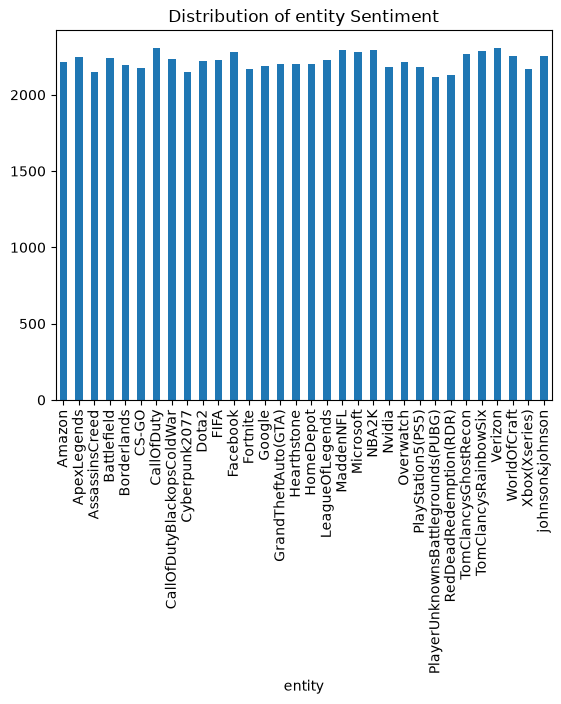

In [39]:
df.groupby("entity").size().plot(kind="bar", title="Distribution of entity Sentiment")

In [18]:
# df.groupby("Borderlands")["Positive"].count()

In [ ]:
# from bs4 import BeautifulSoup

In [ ]:
# df["MESSAGE"] = df["MESSAGE"].apply(lambda x: BeautifulSoup(x, "html.parser").get_text(separator=" "))
# df["MESSAGE"] = df["MESSAGE"].apply(lambda x: BeautifulSoup(x, "lxml").get_text(separator=" "))

In [ ]:
import re

In [ ]:
def remove_html_regex(text):
    # 1. Удаляем блоки <script> и <style> вместе с содержимым
    clean = re.sub(r'<(script|style).*?>.*?</\1>', ' ', text, flags=re.DOTALL)
    # 2. Удаляем все остальные HTML-теги
    clean = re.sub(r'<[^>]+>', ' ', clean)
    # 3. Схлопываем лишние пробелы
    return re.sub(r'\s+', ' ', clean).strip()

In [ ]:
def remove_url(text):
    pattern=re.compile(r'https?://\S+|www\.\S+')
    return pattern.sub(r' ',text)

In [ ]:
df["content"] = df["content"].apply(remove_html_regex)
df["content"] = df["content"].apply(remove_url)

In [40]:
import spacy # Предпочтительнее чем nltk

In [41]:
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"]) # Отключение parser и ner при загрузке для ускорения пайплайна

def preprocess_text(text):

    doc = nlp(text) # Токенизация и лемматизация с помощью spaCy

    tokens = []
    for token in doc:
        if token.is_stop or token.is_punct or token.is_space: # Если токен является стоп-словом, пунктуацией или пробелом, пропускаем его
            continue
        if token.like_num: # Если токен является числом, пропускаем его
            continue
        lemma = token.lemma_.lower().strip()

        if lemma.isalpha() and len(lemma) > 1:
            tokens.append(lemma)

    return ' '.join(tokens)

In [42]:
df['content'] = df['content'].apply(preprocess_text)

In [43]:
df.head()

,entity,sentiment,content
0,Borderlands,Positive,come border kill
1,Borderlands,Positive,get borderland kill
2,Borderlands,Positive,come borderland murder
3,Borderlands,Positive,get borderland murder
4,Borderlands,Positive,get borderland murder


In [44]:
df.duplicated().sum()

np.int64(11594)

In [45]:
df.drop_duplicates(inplace=True)

In [46]:
df.isnull().sum()

entity       0
sentiment    0
content      0
dtype: int64

In [48]:
df["sentiment"].value_counts()

sentiment
Negative      18225
Positive      15758
Neutral       14949
Irrelevant    10534
Name: count, dtype: int64

In [49]:
df["sentiment"] = df["sentiment"].map({"Positive": 2, "Neutral": 1, "Irrelevant": 1, "Negative": 0})

In [52]:
df.duplicated().sum()

np.int64(67)

In [ ]:
df.drop_duplicates(inplace=True) 

In [55]:
df.to_csv('../data/twitter_training_cleaned.csv', index=False)